# Análisis de resultados: SFT y GRPO de Ministral 3 3B en el ambiente de selección sobre árboles

Este notebook reúne los resultados obtenidos hasta ahora y genera las tablas y figuras para el informe. Las figuras se guardan en `figuras/` y las tablas en `figuras/tablas/`.

**Pregunta principal.** ¿Cuánto mejora Ministral 3 3B Reasoning después de un ajuste supervisado (SFT con LoRA), qué tipo de trazas conviene usar para entrenarlo y cuánto agrega después el aprendizaje por refuerzo (GRPO) con la recompensa del ambiente?

| Modelo | Qué es |
| --- | --- |
| Ministral 3 3B Reasoning 4bit | Baseline original, cuantizado (NF4 en Transformers y GGUF Q4_K_M en LM Studio) |
| Ministral 3 3B Reasoning bf16 | El mismo modelo sin cuantizar: el punto de partida justo para los SFT |
| Ministral 3 3B SFT Qwen | SFT con 473 trazas correctas de Qwen 3.5 9B (niveles 2 a 4) |
| Ministral 3 3B SFT solver masivo | SFT con 6.334 trazas de la programación dinámica (niveles 1 a 8) |
| Ministral 3 3B GRPO paso 220 | GRPO con LoRA sobre el SFT solver masivo, checkpoint del paso 220 de 300 (niveles 5 a 8 de `datos/entrenamiento.jsonl`) |
| Ministral 3 3B GRPO | El mismo GRPO al terminar los 300 pasos |
| DeepSeek, Llama, OLMo, Qwen 2B | Baselines de referencia de otros modelos pequeños |

**Protocolo común.** Los 160 árboles de `datos/test.jsonl` (20 por nivel), 4 intentos por árbol, temperatura 0,7, 3400 tokens para razonar y 200 para responder. Se usan solo los intentos 1 a 4 de cada modelo, para que todos tengan el mismo número. Un modelo cuya carpeta todavía no está en `BaseLines/` se omite de las figuras.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd()
BASE = RAIZ / "seleccion_arbol"
assert BASE.exists(), "Ejecuta el notebook desde la raíz del repositorio."
sys.path.insert(0, str(BASE))
from src.evaluacion import leer_resultados, resumir_pass  # noqa: E402

FIGURAS = RAIZ / "figuras"
TABLAS = FIGURAS / "tablas"
TABLAS.mkdir(parents=True, exist_ok=True)

INTENTOS = 4
PRESUPUESTO = 3400
NIVELES = list(range(1, 9))
RNG = np.random.default_rng(0)

# Los Ministral se comparan entre sí; el color sigue al modelo en todas las figuras.
MINISTRAL = {
    "Ministral 3 3B Reasoning 4bit": dict(corto="Base 4 bits", color="#257de0", marcador="o"),
    "Ministral 3 3B Reasoning bf16": dict(corto="Base bf16", color="#f47230", marcador="s"),
    "Ministral 3 3B SFT Qwen": dict(corto="SFT trazas Qwen", color="#00b894", marcador="^"),
    "Ministral 3 3B SFT solver masivo": dict(corto="SFT trazas solver", color="#f2a600", marcador="D"),
    "Ministral 3 3B GRPO paso 220": dict(corto="GRPO paso 220", color="#b18cf0", marcador="v"),
    "Ministral 3 3B GRPO": dict(corto="GRPO 300 pasos", color="#7340d8", marcador="P"),
}
GRIS = "#a3a3a3"
TEXTO, TEXTO_2 = "#191919", "#666666"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#cccccc", "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ececec", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})
pd.set_option("display.width", 200)


def guardar(figura, nombre):
    figura.savefig(FIGURAS / f"{nombre}.png")


def guardar_tabla(tabla, nombre):
    tabla.to_csv(TABLAS / f"{nombre}.csv")
    return tabla

## 1. Datos

In [2]:
filas = []
for ruta in sorted((BASE / "BaseLines").glob("*/baseline_test.jsonl")):
    filas += leer_resultados(ruta)
datos = pd.DataFrame(filas)
datos = datos[datos["intento"] <= INTENTOS].copy()

datos["optimo"] = datos["recompensa"] == 1.0
datos["invalida"] = datos["recompensa"] == -1.0
datos["forzada"] = datos["respuesta_forzada"].fillna(False).astype(bool)
datos["supera_atajos"] = datos["puntaje"].notna() & (datos["puntaje"] > datos["puntaje_referencia"])
datos["arbol"] = datos["episodio"]

MODELOS = sorted(datos["modelo"].unique(), key=lambda m: (m not in MINISTRAL, list(MINISTRAL).index(m) if m in MINISTRAL else m))
cobertura = datos.pivot_table(index="modelo", columns="nivel", values="recompensa", aggfunc="size").reindex(MODELOS)
print("Intentos por modelo y nivel (80 = nivel completo):")
display(cobertura)
faltan = [m for m in MINISTRAL if m not in MODELOS]
if faltan:
    print("Faltan los resultados de:", faltan, "- trae BaseLines/ desde el cluster.")

Intentos por modelo y nivel (80 = nivel completo):


nivel,1,2,3,4,5,6,7,8
modelo,,,,,,,,
Ministral 3 3B Reasoning 4bit,80,80,80,80,80,80,80,80
Ministral 3 3B Reasoning bf16,80,80,80,80,80,80,80,80
Ministral 3 3B SFT Qwen,80,80,80,80,80,80,80,80
Ministral 3 3B SFT solver masivo,80,80,80,80,80,80,80,80
DeepSeek R1 Distill 1.5B,80,80,80,80,80,80,80,80
Llama 3.2 1B,80,80,80,80,80,80,80,80
OLMo 2 1B,80,80,80,80,80,80,80,80
Qwen 3.5 2B,80,80,80,80,80,80,80,80


## 2. Intervalos de confianza

Los intentos de un mismo árbol no son independientes, así que los intervalos se calculan con *bootstrap por árbol*: se remuestrean los 20 árboles de cada nivel con reemplazo, 2000 veces, y se toman los percentiles 2,5 y 97,5. Para comparar dos modelos se usa la diferencia *pareada* por árbol, porque todos los modelos respondieron los mismos árboles.

In [3]:
REPETICIONES = 2000


def exito_por_arbol(modelo, columna="optimo"):
    # Una fila por árbol: la proporción de sus intentos que cumple la condición.
    d = datos[datos["modelo"] == modelo]
    return d.groupby(["nivel", "arbol"])[columna].mean()


def bootstrap(por_arbol, niveles=None):
    # Remuestrea árboles dentro de cada nivel. Devuelve (estimación, inferior, superior).
    por_arbol = por_arbol if niveles is None else por_arbol[por_arbol.index.get_level_values("nivel").isin(niveles)]
    grupos = [g.to_numpy() for _, g in por_arbol.groupby(level="nivel")]
    muestras = np.zeros(REPETICIONES)
    for g in grupos:
        indices = RNG.integers(0, len(g), size=(REPETICIONES, len(g)))
        muestras += g[indices].mean(axis=1) * len(g)
    muestras /= sum(len(g) for g in grupos)
    return por_arbol.mean(), *np.percentile(muestras, [2.5, 97.5])


def ic_por_nivel(modelo, columna="optimo"):
    por_arbol = exito_por_arbol(modelo, columna)
    return pd.DataFrame(
        [bootstrap(por_arbol, [n]) for n in NIVELES], index=pd.Index(NIVELES, name="nivel"),
        columns=["estimacion", "inferior", "superior"],
    )

## 3. Resultado global

In [4]:
def resumen_modelo(m):
    d = datos[datos["modelo"] == m]
    p1, inf, sup = bootstrap(exito_por_arbol(m))
    return {
        "pass@1": p1, "IC 95% inf": inf, "IC 95% sup": sup,
        "recompensa media": d["recompensa"].mean(),
        "supera atajos": d["supera_atajos"].mean(),
        "inválidas": d["invalida"].mean(),
        "forzadas (cortes)": d["forzada"].mean(),
        "tokens medios": d["tokens"].mean(),
        "segundos medios": d["segundos"].mean(),
    }

pass4 = resumir_pass(
    [BASE / "BaseLines" / m / "baseline_test.jsonl" for m in MODELOS], k=INTENTOS, por=("modelo",), intentos=INTENTOS
)["pass@4"]
global_ = pd.DataFrame({m: resumen_modelo(m) for m in MODELOS}).T
global_.insert(3, "pass@4", pass4.reindex(global_.index))
global_ = guardar_tabla(global_.sort_values("pass@1", ascending=False), "resumen_global")
display(global_.style.format({c: "{:.3f}" for c in global_.columns if c not in ("tokens medios", "segundos medios")}
                             | {"tokens medios": "{:.0f}", "segundos medios": "{:.1f}"}))

,pass@1,IC 95% inf,IC 95% sup,pass@4,recompensa media,supera atajos,inválidas,forzadas (cortes),tokens medios,segundos medios
Ministral 3 3B SFT solver masivo,0.664,0.631,0.697,0.775,0.897,0.719,0.000,0.005,506,8.5
Ministral 3 3B SFT Qwen,0.433,0.405,0.459,0.588,0.577,0.347,0.047,0.617,2666,44.5
Ministral 3 3B Reasoning bf16,0.325,0.297,0.353,0.475,0.129,0.205,0.316,0.648,2931,46.8
Ministral 3 3B Reasoning 4bit,0.292,0.266,0.319,0.475,0.328,0.191,0.123,0.717,3124,135.3
DeepSeek R1 Distill 1.5B,0.086,0.058,0.116,0.169,0.255,0.056,0.020,0.983,3404,91.8
OLMo 2 1B,0.062,0.033,0.094,0.075,-0.082,0.019,0.278,0.000,19,3.7
Llama 3.2 1B,0.059,0.033,0.089,0.100,0.235,0.033,0.000,0.000,5,2.0
Qwen 3.5 2B,0.059,0.037,0.083,0.125,0.178,0.017,0.048,1.000,3414,88.5


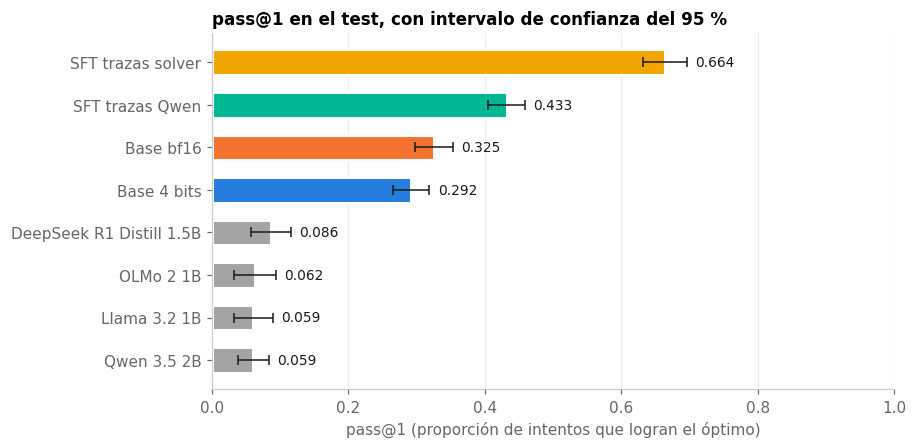

In [5]:
orden = global_.index[::-1]
figura, eje = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(orden))
colores = [MINISTRAL[m]["color"] if m in MINISTRAL else GRIS for m in orden]
eje.barh(y, global_.loc[orden, "pass@1"], height=0.6, color=colores, edgecolor="white", linewidth=2)
eje.errorbar(
    global_.loc[orden, "pass@1"], y,
    xerr=[global_.loc[orden, "pass@1"] - global_.loc[orden, "IC 95% inf"], global_.loc[orden, "IC 95% sup"] - global_.loc[orden, "pass@1"]],
    fmt="none", ecolor=TEXTO, elinewidth=1, capsize=3,
)
for i, m in enumerate(orden):
    eje.text(global_.loc[m, "IC 95% sup"] + 0.012, i, f"{global_.loc[m, 'pass@1']:.3f}", va="center", color=TEXTO, fontsize=9)
eje.set_yticks(y, [MINISTRAL[m]["corto"] if m in MINISTRAL else m for m in orden])
eje.set_xlim(0, 1)
eje.set_xlabel("pass@1 (proporción de intentos que logran el óptimo)")
eje.grid(axis="y", visible=False)
eje.set_title("pass@1 en el test, con intervalo de confianza del 95 %")
guardar(figura, "01_pass1_global")
plt.show()

## 4. Resultado por nivel

In [6]:
por_nivel = {m: ic_por_nivel(m) for m in MINISTRAL if m in MODELOS}
tabla_p1 = guardar_tabla(datos.pivot_table(index="modelo", columns="nivel", values="optimo", aggfunc="mean").reindex(MODELOS), "pass1_por_nivel")
tabla_p4 = guardar_tabla(
    resumir_pass([BASE / "BaseLines" / m / "baseline_test.jsonl" for m in MODELOS], k=INTENTOS, intentos=INTENTOS)["pass@4"].unstack().reindex(MODELOS),
    "pass4_por_nivel",
)
print("pass@1 por nivel"); display(tabla_p1.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0, vmax=1))
print("pass@4 por nivel"); display(tabla_p4.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

pass@1 por nivel


nivel,1,2,3,4,5,6,7,8
modelo,,,,,,,,
Ministral 3 3B Reasoning 4bit,0.875,0.675,0.500,0.188,0.100,0.000,0.000,0.000
Ministral 3 3B Reasoning bf16,0.825,0.887,0.512,0.212,0.150,0.013,0.000,0.000
Ministral 3 3B SFT Qwen,0.963,0.825,0.838,0.550,0.250,0.037,0.000,0.000
Ministral 3 3B SFT solver masivo,1.000,0.988,0.912,0.950,0.863,0.375,0.212,0.013
DeepSeek R1 Distill 1.5B,0.325,0.237,0.125,0.000,0.000,0.000,0.000,0.000
Llama 3.2 1B,0.287,0.188,0.000,0.000,0.000,0.000,0.000,0.000
OLMo 2 1B,0.275,0.225,0.000,0.000,0.000,0.000,0.000,0.000
Qwen 3.5 2B,0.287,0.175,0.013,0.000,0.000,0.000,0.000,0.000


pass@4 por nivel


nivel,1,2,3,4,5,6,7,8
modelo,,,,,,,,
Ministral 3 3B Reasoning 4bit,1.000,1.000,0.950,0.450,0.400,0.000,0.000,0.000
Ministral 3 3B Reasoning bf16,0.950,1.000,0.900,0.550,0.350,0.050,0.000,0.000
Ministral 3 3B SFT Qwen,1.000,1.000,1.000,0.900,0.650,0.150,0.000,0.000
Ministral 3 3B SFT solver masivo,1.000,1.000,1.000,0.950,0.950,0.700,0.550,0.050
DeepSeek R1 Distill 1.5B,0.500,0.450,0.400,0.000,0.000,0.000,0.000,0.000
Llama 3.2 1B,0.450,0.350,0.000,0.000,0.000,0.000,0.000,0.000
OLMo 2 1B,0.350,0.250,0.000,0.000,0.000,0.000,0.000,0.000
Qwen 3.5 2B,0.500,0.450,0.050,0.000,0.000,0.000,0.000,0.000


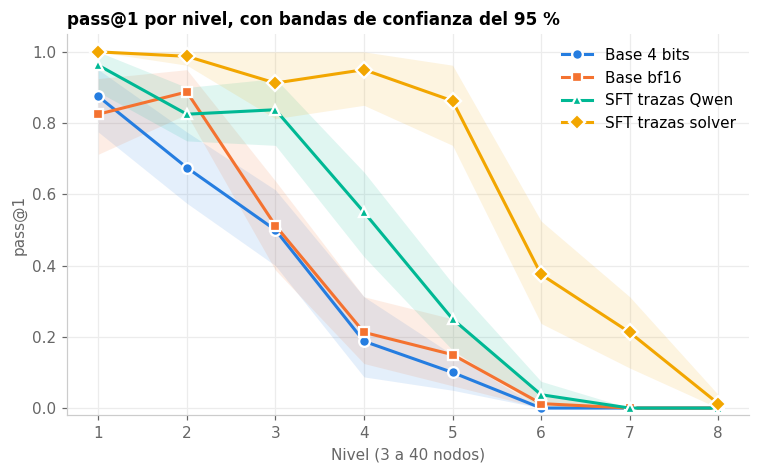

In [7]:
def lineas_por_nivel(eje, series, etiqueta_y, referencia=None):
    # Una línea por modelo, con banda de confianza si la hay y etiqueta directa al final.
    for m, s in series.items():
        estilo = MINISTRAL[m]
        valores = s["estimacion"] if isinstance(s, pd.DataFrame) else s
        if isinstance(s, pd.DataFrame):
            eje.fill_between(s.index, s["inferior"], s["superior"], color=estilo["color"], alpha=0.12, linewidth=0)
        eje.plot(valores.index, valores.values, color=estilo["color"], marker=estilo["marcador"],
                 markeredgecolor="white", markeredgewidth=1.5, markersize=7, label=estilo["corto"])
    if referencia is not None:
        eje.axhline(referencia[0], color=TEXTO_2, linewidth=1, linestyle="--")
        eje.text(1.05, referencia[0], referencia[1], color=TEXTO_2, fontsize=8, va="bottom")
    eje.set_xticks(NIVELES)
    eje.set_xlabel("Nivel (3 a 40 nodos)")
    eje.set_ylabel(etiqueta_y)
    eje.legend(loc="upper right")


figura, eje = plt.subplots(figsize=(8, 4.5))
lineas_por_nivel(eje, por_nivel, "pass@1")
eje.set_ylim(-0.02, 1.05)
eje.set_title("pass@1 por nivel, con bandas de confianza del 95 %")
guardar(figura, "02_pass1_por_nivel")
plt.show()

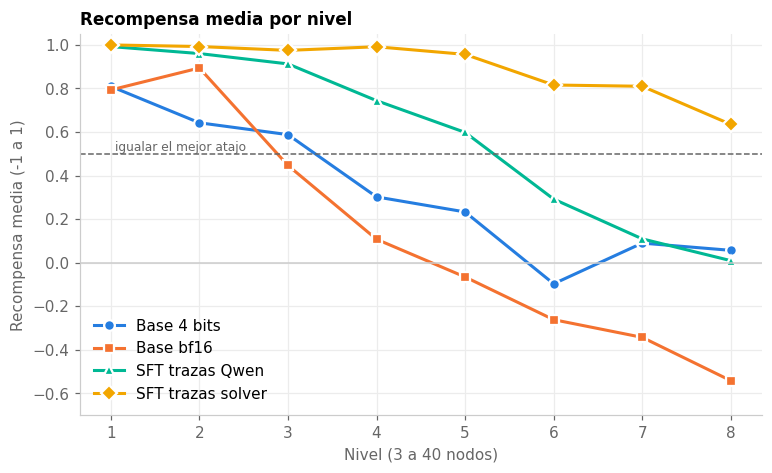

In [8]:
recompensa_nivel = {m: datos[datos["modelo"] == m].groupby("nivel")["recompensa"].mean() for m in MINISTRAL if m in MODELOS}
figura, eje = plt.subplots(figsize=(8, 4.5))
lineas_por_nivel(eje, recompensa_nivel, "Recompensa media (-1 a 1)", referencia=(0.5, "igualar el mejor atajo"))
eje.axhline(0, color="#cccccc", linewidth=1)
eje.set_ylim(-0.7, 1.05)
eje.legend(loc="lower left")
eje.set_title("Recompensa media por nivel")
guardar(figura, "03_recompensa_por_nivel")
plt.show()

## 5. Cómo responden: desglose de los intentos

Cada intento cae en una de cuatro categorías: **óptimo**, **válido sobre el mejor atajo** (mejor que las reglas simples pero sin llegar al óptimo), **válido sin superar los atajos** e **inválido** (sin lista legible, nodos fuera de rango o lista cortada).

In [ ]:
CATEGORIAS = {
    "Óptimo": "#0e3d7e",
    "Sobre el mejor atajo": "#338ced",
    "Sin superar los atajos": "#b6d5f8",
    "Inválido": "#7a7a7a",
}


def categoria(fila):
    if fila["invalida"]:
        return "Inválido"
    if fila["optimo"]:
        return "Óptimo"
    return "Sobre el mejor atajo" if fila["supera_atajos"] else "Sin superar los atajos"


datos["categoria"] = datos.apply(categoria, axis=1)
presentes = [m for m in MINISTRAL if m in MODELOS]
# Una grilla de hasta 3 paneles por fila, para que la figura no crezca solo a lo ancho.
columnas = min(3, len(presentes))
filas_figura = -(-len(presentes) // columnas)
figura, ejes = plt.subplots(filas_figura, columnas, figsize=(3.4 * columnas, 3.6 * filas_figura), sharey=True, squeeze=False)
for eje, m in zip(ejes.flat, presentes):
    reparto = datos[datos["modelo"] == m].groupby("nivel")["categoria"].value_counts(normalize=True).unstack().reindex(index=NIVELES, columns=CATEGORIAS).fillna(0)
    abajo = np.zeros(len(reparto))
    for nombre, color in CATEGORIAS.items():
        eje.bar(reparto.index, reparto[nombre], bottom=abajo, color=color, width=0.75, edgecolor="white", linewidth=1, label=nombre)
        abajo += reparto[nombre].to_numpy()
    eje.set_title(MINISTRAL[m]["corto"], fontsize=10)
    eje.set_xticks(NIVELES)
    eje.set_xlabel("Nivel")
    eje.grid(axis="x", visible=False)
for eje in ejes.flat[len(presentes):]:
    eje.set_visible(False)
for eje in ejes[:, 0]:
    eje.set_ylabel("Proporción de intentos")
figura.legend(*ejes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
figura.tight_layout()
guardar(figura, "04_desglose_por_nivel")
plt.show()

guardar_tabla(datos.groupby(["modelo", "nivel"])["categoria"].value_counts(normalize=True).unstack().reindex(columns=CATEGORIAS).fillna(0), "desglose_por_nivel")

## 6. Costo: tokens y respuestas forzadas

Si un intento agota los 3400 tokens de razonamiento, el ambiente escribe `<respuesta>` y le da 200 tokens más para completar la lista (*respuesta forzada*). Un modelo que se corta seguido gasta más cómputo y depende de esa respuesta forzada.

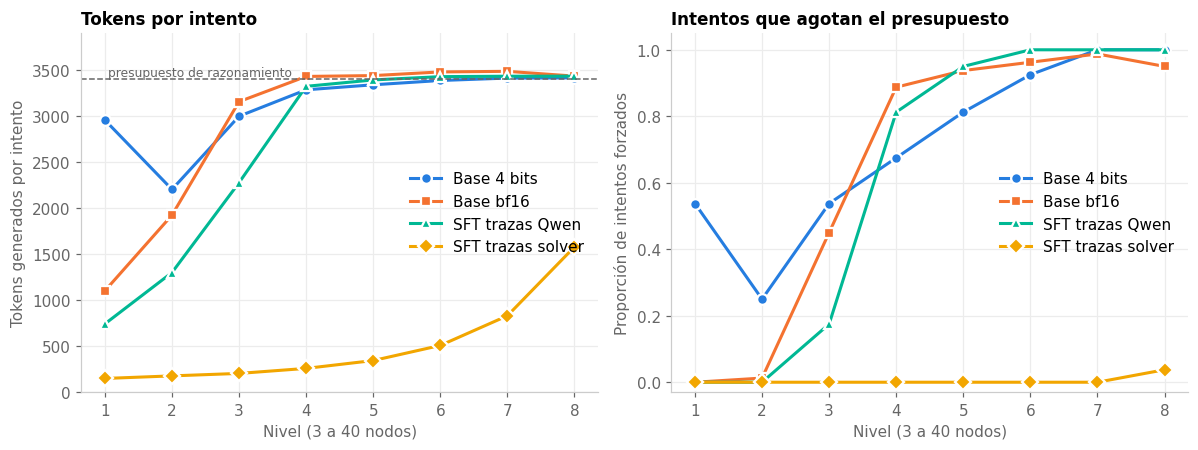

In [10]:
tokens_nivel = {m: datos[datos["modelo"] == m].groupby("nivel")["tokens"].mean() for m in presentes}
forzadas_nivel = {m: datos[datos["modelo"] == m].groupby("nivel")["forzada"].mean() for m in presentes}

figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(11, 4.2))
lineas_por_nivel(eje_a, tokens_nivel, "Tokens generados por intento", referencia=(PRESUPUESTO, "presupuesto de razonamiento"))
eje_a.set_ylim(0, 3900)
eje_a.legend(loc="center right")
eje_a.set_title("Tokens por intento")
lineas_por_nivel(eje_b, forzadas_nivel, "Proporción de intentos forzados")
eje_b.set_ylim(-0.03, 1.05)
eje_b.legend(loc="center right")
eje_b.set_title("Intentos que agotan el presupuesto")
figura.tight_layout()
guardar(figura, "05_tokens_y_cortes")
plt.show()

### Efecto de la respuesta forzada en la validez

Al forzar la respuesta, `ModeloTransformers` solo cierra un razonamiento abierto con `<think>`. Ministral razona dentro de `[THINK]`, así que ese bloque queda abierto: el modelo base suele seguir razonando y agota los 200 tokens sin escribir la lista. La tabla mide cuánto pesa esto en cada modelo. Es una limitación de la evaluación, no del modelo, y afecta sobre todo al modelo base en bf16: el 45 % de sus intentos forzados son inválidos, contra 12 % en 4 bits (cuya parte en LM Studio sí cierra `[THINK]`) y 8 % en el SFT con Qwen, que aprendió a razonar sin ese bloque. También acierta menos cuando lo fuerzan (pass@1 de 0,08 entre forzados, contra 0,16 a 0,18 de los otros), así que su pass@1 probablemente está algo subestimado.

In [11]:
def efecto_forzada(m):
    d = datos[datos["modelo"] == m]
    f, nf = d[d["forzada"]], d[~d["forzada"]]
    return {
        "intentos forzados": d["forzada"].mean(),
        "inválidas entre forzados": f["invalida"].mean() if len(f) else np.nan,
        "inválidas entre no forzados": nf["invalida"].mean() if len(nf) else np.nan,
        "pass@1 entre forzados": f["optimo"].mean() if len(f) else np.nan,
        "pass@1 entre no forzados": nf["optimo"].mean() if len(nf) else np.nan,
    }

forzadas = guardar_tabla(pd.DataFrame({m: efecto_forzada(m) for m in presentes}).T, "respuestas_forzadas")
display(forzadas.style.format("{:.3f}"))

,intentos forzados,inválidas entre forzados,inválidas entre no forzados,pass@1 entre forzados,pass@1 entre no forzados
Ministral 3 3B Reasoning 4bit,0.717,0.124,0.122,0.176,0.586
Ministral 3 3B Reasoning bf16,0.648,0.446,0.076,0.084,0.769
Ministral 3 3B SFT Qwen,0.617,0.076,0.000,0.165,0.865
Ministral 3 3B SFT solver masivo,0.005,0.000,0.000,0.000,0.667


## 7. ¿Las mejoras son significativas?

Diferencia pareada de pass@1 frente al modelo base en bf16, árbol por árbol. Si el intervalo no cruza el 0, la diferencia es significativa al 95 %. Se compara contra bf16 y no contra 4 bits, porque los SFT y el GRPO también corren en bf16.

In [ ]:
REFERENCIA = "Ministral 3 3B Reasoning bf16"


def diferencia_pareada(m, niveles, referencia=REFERENCIA):
    a, b = exito_por_arbol(m), exito_por_arbol(referencia)
    comun = a.index.intersection(b.index)
    return bootstrap((a.loc[comun] - b.loc[comun]).rename("dif"), niveles)


def tabla_diferencias(modelos, referencia):
    # Una fila por modelo y nivel, más una con todos los niveles juntos.
    filas = []
    for m in modelos:
        for nivel in ["todos"] + NIVELES:
            est, inf, sup = diferencia_pareada(m, NIVELES if nivel == "todos" else [nivel], referencia)
            filas.append({"modelo": m, "nivel": nivel, "diferencia": est, "IC 95% inf": inf, "IC 95% sup": sup,
                          "significativa": (inf > 0) or (sup < 0)})
    return pd.DataFrame(filas).set_index(["modelo", "nivel"])


def grafico_diferencias(eje, diferencias, modelos):
    desplazamiento = np.linspace(-0.25, 0.25, len(modelos)) if len(modelos) > 1 else [0.0]
    for d_x, m in zip(desplazamiento, modelos):
        t = diferencias.loc[m].drop("todos")
        x = np.array(NIVELES) + d_x
        eje.errorbar(x, t["diferencia"], yerr=[t["diferencia"] - t["IC 95% inf"], t["IC 95% sup"] - t["diferencia"]],
                     fmt=MINISTRAL[m]["marcador"], color=MINISTRAL[m]["color"], markeredgecolor="white", markersize=7,
                     elinewidth=1.5, capsize=0, label=MINISTRAL[m]["corto"])
    eje.axhline(0, color=TEXTO_2, linewidth=1)
    eje.set_xticks(NIVELES)
    eje.set_xlabel("Nivel")
    eje.legend(loc="upper left")


FORMATO_DIFERENCIAS = {"diferencia": "{:+.3f}", "IC 95% inf": "{:+.3f}", "IC 95% sup": "{:+.3f}"}
comparados = [m for m in presentes if m != REFERENCIA]
diferencias = guardar_tabla(tabla_diferencias(comparados, REFERENCIA), "diferencias_vs_bf16")
display(diferencias.loc[(slice(None), "todos"), :].style.format(FORMATO_DIFERENCIAS))

figura, eje = plt.subplots(figsize=(8, 4.2))
grafico_diferencias(eje, diferencias, comparados)
eje.set_ylabel("Diferencia de pass@1 frente a bf16")
eje.set_title("Mejora sobre el modelo base en bf16, con intervalo del 95 %")
guardar(figura, "06_diferencia_vs_bf16")
plt.show()

### ¿Cuánto agrega el GRPO sobre el SFT?

El GRPO parte del SFT solver masivo, así que su comparación justa es contra ese modelo, árbol por árbol. El GRPO entrenó solo con los niveles 5 a 8: en esos niveles se espera la mejora, y en los niveles 1 a 4 basta con que no empeore.

In [ ]:
SFT_SOLVER = "Ministral 3 3B SFT solver masivo"
grpo = [m for m in presentes if m.startswith("Ministral 3 3B GRPO")]
if SFT_SOLVER in presentes and grpo:
    diferencias_grpo = guardar_tabla(tabla_diferencias(grpo, SFT_SOLVER), "diferencias_grpo_vs_sft")
    print("Diferencia de pass@1 frente al SFT solver masivo")
    display(diferencias_grpo.style.format(FORMATO_DIFERENCIAS))

    figura, eje = plt.subplots(figsize=(8, 4.2))
    grafico_diferencias(eje, diferencias_grpo, grpo)
    eje.axvspan(4.5, 8.5, color="#f1ecfd", zorder=0)
    eje.text(4.6, eje.get_ylim()[1], "niveles entrenados con GRPO", color=TEXTO_2, fontsize=8, va="top")
    eje.set_ylabel("Diferencia de pass@1 frente al SFT solver")
    eje.set_title("Mejora del GRPO sobre su punto de partida, con intervalo del 95 %")
    guardar(figura, "08_grpo_vs_sft")
    plt.show()
else:
    print("Falta el SFT solver masivo o algún GRPO en BaseLines/: no hay comparación.")

## 8. Entrenamientos

In [13]:
import json

ENTRENAMIENTOS = {
    "05_sft_ministral": ("Ministral 3 3B SFT Qwen", "datos/sft.jsonl"),
    "06_sft_ministral_solver": ("Ministral 3 3B SFT solver", "datos/sft_solver.jsonl"),
    "07_sft_ministral_solver_masivo": ("Ministral 3 3B SFT solver masivo", "datos/sft_solver_masivo.jsonl"),
}
filas_ent = []
for carpeta, (modelo, ruta_datos) in ENTRENAMIENTOS.items():
    ruta = BASE / "resultados" / carpeta
    if not (ruta / "perdida.csv").exists():
        continue
    configuracion = json.loads((ruta / "configuracion.json").read_text(encoding="utf-8"))
    perdida = pd.read_csv(ruta / "perdida.csv")
    validacion = perdida[perdida["conjunto"] == "validacion"]
    filas_ent.append({
        "entrenamiento": carpeta, "datos": configuracion["datos"], "épocas": configuracion["epocas"],
        "lote efectivo": configuracion["lote"] * configuracion["acumulacion"], "rango LoRA": configuracion["rango_lora"],
        "learning rate": configuracion["tasa"], "pasos": int(perdida["paso"].max()),
        "pérdida validación inicial": validacion["perdida"].iloc[0], "pérdida validación final": validacion["perdida"].iloc[-1],
    })
entrenamientos = guardar_tabla(pd.DataFrame(filas_ent).set_index("entrenamiento"), "entrenamientos")
display(entrenamientos)

,datos,épocas,lote efectivo,rango LoRA,learning rate,pasos,pérdida validación inicial,pérdida validación final
entrenamiento,,,,,,,,
05_sft_ministral,datos/sft.jsonl,3.0,16,64,0.0001,87,0.379066,0.298409
07_sft_ministral_solver_masivo,datos/sft_solver_masivo.jsonl,1.0,32,64,0.0001,194,0.073676,0.018794


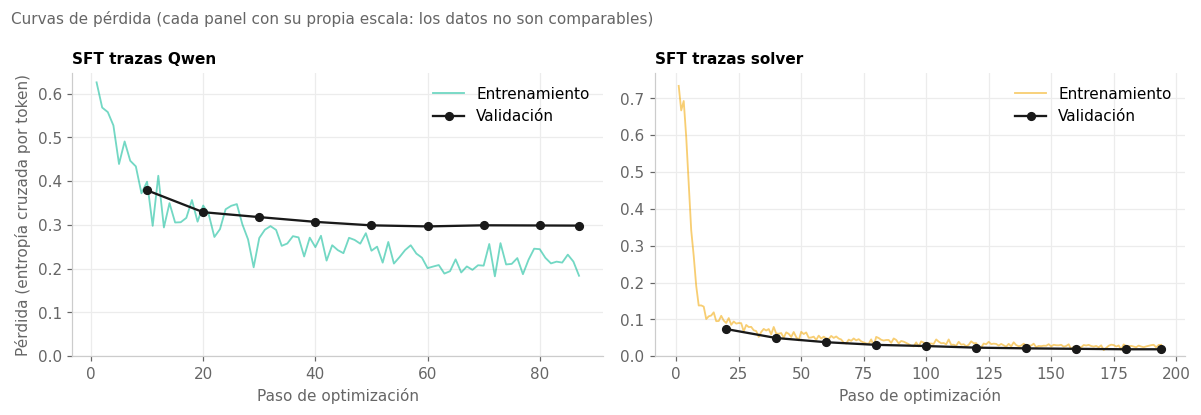

In [14]:
curvas = [c for c in ENTRENAMIENTOS if (BASE / "resultados" / c / "perdida.csv").exists()]
figura, ejes = plt.subplots(1, len(curvas), figsize=(5.5 * len(curvas), 3.8))
for eje, carpeta in zip(np.atleast_1d(ejes), curvas):
    perdida = pd.read_csv(BASE / "resultados" / carpeta / "perdida.csv")
    color = MINISTRAL.get(ENTRENAMIENTOS[carpeta][0], {"color": GRIS})["color"]
    ent = perdida[perdida["conjunto"] == "entrenamiento"]
    val = perdida[perdida["conjunto"] == "validacion"]
    eje.plot(ent["paso"], ent["perdida"], color=color, linewidth=1.2, alpha=0.55, label="Entrenamiento")
    eje.plot(val["paso"], val["perdida"], color=TEXTO, marker="o", markersize=5, linewidth=1.5, label="Validación")
    eje.set_title(MINISTRAL.get(ENTRENAMIENTOS[carpeta][0], {"corto": carpeta})["corto"], fontsize=10)
    eje.set_xlabel("Paso de optimización")
    eje.set_ylim(bottom=0)
    eje.legend(loc="upper right")
np.atleast_1d(ejes)[0].set_ylabel("Pérdida (entropía cruzada por token)")
figura.suptitle("Curvas de pérdida (cada panel con su propia escala: los datos no son comparables)", x=0.01, ha="left", fontsize=10, color=TEXTO_2)
figura.tight_layout()
guardar(figura, "07_curvas_de_perdida")
plt.show()

In [15]:
# Las trazas de cada SFT: cuántas hay por nivel y cuán largas son.
def trazas(ruta):
    ruta = BASE / ruta
    if not ruta.exists():
        return None
    filas = [json.loads(l) for l in ruta.read_text(encoding="utf-8").splitlines() if l.strip()]
    d = pd.DataFrame({"nivel": [f["nivel"] for f in filas], "caracteres": [len(f["messages"][-1]["content"]) for f in filas]})
    return d.groupby("nivel").agg(trazas=("caracteres", "size"), caracteres_medios=("caracteres", "mean")).round(0)

for carpeta, (modelo, ruta_datos) in ENTRENAMIENTOS.items():
    t = trazas(ruta_datos)
    if t is not None:
        print(f"{ruta_datos} ({MINISTRAL.get(modelo, {'corto': modelo})['corto']})")
        display(t.T)
    else:
        print(f"{ruta_datos}: no está en esta copia (se genera con src.trazas.construir_solver).")

datos/sft.jsonl (SFT trazas Qwen)


nivel,2,3,4
trazas,250.0,200.0,23.0
caracteres_medios,2929.0,5659.0,7377.0


datos/sft_solver.jsonl (Ministral 3 3B SFT solver)


nivel,2,3,4
trazas,250.0,200.0,23.0
caracteres_medios,442.0,484.0,568.0


datos/sft_solver_masivo.jsonl: no está en esta copia (se genera con src.trazas.construir_solver).


### Entrenamiento con GRPO

En cada paso, el GRPO toma 16 problemas de los niveles 5 a 8 de `datos/entrenamiento.jsonl`, genera 8 respuestas por problema con temperatura 1,0 y un máximo de 2048 tokens, y las califica con `reward` (`seleccion_arbol/entrenar_grpo.py`). Las cifras de esta sección son de esas respuestas de entrenamiento: con temperatura 1,0 y sin respuesta forzada, no se comparan directamente con el pass@1 del test. Lo que importa es su evolución a lo largo de los pasos.

In [ ]:
CARPETA_GRPO = BASE / "resultados" / "08_grpo_ministral"
BLOQUE_GRPO = 20  # Pasos que se promedian en cada punto
COLORES_NIVEL = {"5": "#d4c4f7", "6": "#b18cf0", "7": "#8a5ce6", "8": "#5b2bb5", "todos": TEXTO}


def orden_nivel(nivel):
    return (nivel == "todos", int(nivel) if nivel != "todos" else 0)


if (CARPETA_GRPO / "metricas.csv").exists():
    configuracion_grpo = json.loads((CARPETA_GRPO / "configuracion.json").read_text(encoding="utf-8"))
    metricas_grpo = pd.read_csv(CARPETA_GRPO / "metricas.csv", dtype={"nivel": str})
    metricas_grpo["bloque"] = metricas_grpo["paso"] // BLOQUE_GRPO

    # Promedio de cada bloque, ponderado por las respuestas de cada paso: no todos los pasos tienen los cuatro niveles.
    ponderadas = metricas_grpo.assign(
        recompensa=metricas_grpo["recompensa_media"] * metricas_grpo["respuestas"],
        optimas=metricas_grpo["optimas"] * metricas_grpo["respuestas"],
    ).groupby(["bloque", "nivel"])[["recompensa", "optimas", "respuestas"]].sum()
    por_bloque = ponderadas[["recompensa", "optimas"]].div(ponderadas["respuestas"], axis=0)

    niveles_grpo = sorted(metricas_grpo["nivel"].unique(), key=orden_nivel)
    primero, ultimo = por_bloque.index.get_level_values("bloque").min(), por_bloque.index.get_level_values("bloque").max()
    resumen_grpo = pd.DataFrame({
        "recompensa inicial": por_bloque.loc[primero, "recompensa"],
        "recompensa final": por_bloque.loc[ultimo, "recompensa"],
        "óptimas inicial": por_bloque.loc[primero, "optimas"],
        "óptimas final": por_bloque.loc[ultimo, "optimas"],
    }).reindex(niveles_grpo)
    resumen_grpo.index.name = "nivel"
    guardar_tabla(resumen_grpo, "entrenamiento_grpo")
    print(f"{metricas_grpo['paso'].max() + 1} pasos; primer y último bloque de {BLOQUE_GRPO} pasos. Hiperparámetros:")
    display(pd.Series({clave: configuracion_grpo[clave] for clave in
                       ("sft", "niveles", "pasos", "problemas", "generaciones", "tokens", "temperatura", "tasa", "beta", "rango_lora")},
                      name="valor").to_frame())
    display(resumen_grpo.style.format("{:.3f}"))

    figura, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
    for eje, columna, titulo in ((ejes[0], "recompensa", "Recompensa media"), (ejes[1], "optimas", "Fracción de respuestas óptimas")):
        for nivel in niveles_grpo:
            serie = por_bloque.xs(nivel, level="nivel")[columna]
            eje.plot((serie.index + 1) * BLOQUE_GRPO, serie.values, color=COLORES_NIVEL.get(nivel, GRIS), marker="o",
                     markersize=4, linewidth=2.5 if nivel == "todos" else 1.8,
                     label="Todos" if nivel == "todos" else f"Nivel {nivel}")
        eje.set_xlabel("Paso de optimización (promedio de cada bloque de 20)")
        eje.set_title(titulo)
    ejes[0].set_ylabel("Recompensa (-1 a 1)")
    ejes[1].set_ylabel("Proporción")
    ejes[1].legend(loc="upper left", ncol=2)
    figura.suptitle("Entrenamiento con GRPO: respuestas de entrenamiento (temperatura 1,0)", x=0.01, ha="left", fontsize=10, color=TEXTO_2)
    figura.tight_layout()
    guardar(figura, "09_entrenamiento_grpo")
    plt.show()
else:
    print(f"No está {CARPETA_GRPO / 'metricas.csv'}: trae resultados/08_grpo_ministral desde el cluster.")

## 9. Conclusiones

Los números citados vienen de las tablas anteriores (evaluaciones del 24 y 25 de noviembre de 2026).

1. **El SFT con trazas del solver es la mejora más grande.** Sube el pass@1 de 0,325 (base bf16) a 0,664 y el pass@4 de 0,475 a 0,775. En los niveles 4 y 5, que el modelo base casi nunca resolvía (0,21 y 0,15), pasa a 0,95 y 0,86. Es el único modelo que acierta en los niveles 6 a 8 con alguna regularidad (0,38, 0,21 y 0,01).
2. **El SFT con trazas de Qwen también mejora, pero menos.** Llega a 0,433 de pass@1, con su ganancia concentrada en los niveles 3 a 5, cerca de los niveles 2 a 4 de sus trazas. En los niveles 6 a 8 no mejora: casi siempre agota los 3400 tokens.
3. **El costo cae mucho con las trazas del solver.** Usa 506 tokens por intento en promedio, contra 2.931 del base en bf16 y 2.666 del SFT con Qwen, y casi nunca agota el presupuesto (0,5 % de intentos forzados). Resuelve más árboles con una fracción del cómputo.
4. **El límite del SFT solver son las cuentas largas.** Nunca entrega una respuesta inválida y en los niveles 6 a 8 casi siempre supera a los atajos (0,89, 0,85 y 0,65), pero rara vez llega al óptimo: con 25 o 40 nodos, un error en una de las decenas de sumas encadenadas cambia la selección final.
5. **Las dos mejoras son significativas.** Frente al base en bf16, con diferencia pareada por árbol: el SFT con Qwen suma +0,108 de pass@1 (IC 95 %: +0,066 a +0,147) y el SFT solver +0,339 (+0,295 a +0,380). Entre 4 bits y bf16 la diferencia no es significativa (-0,033; -0,064 a +0,003).
6. **La cuantización y la evaluación influyen en la comparación.** El base en bf16 y en 4 bits tienen pass@1 parecido (0,325 y 0,292), pero bf16 tiene muchas más respuestas inválidas (31,6 %) por la respuesta forzada sin cerrar `[THINK]` (sección 6). Por eso su recompensa media (0,129) no refleja bien su capacidad, y los SFT se comparan contra él por pass@1.
7. **El GRPO sobre el SFT solver sigue mejorando donde el SFT se quedaba corto.** En el test, el checkpoint del paso 220 sube el pass@1 de 0,664 a 0,706 y la recompensa media de 0,897 a 0,933. La ganancia está en los niveles con los que entrenó: el nivel 6 pasa de 0,38 a 0,53, el 7 de 0,21 a 0,29 y el 8 de 0,01 a 0,08. Los niveles 1 a 4, que no vio en el GRPO, se mantienen (diferencias de 1 o 2 intentos de 80), y deja de agotar el presupuesto (0 % de intentos forzados). Durante el entrenamiento, la fracción de respuestas óptimas sube de 0,31 en los primeros 20 pasos a 0,47 en los últimos 20, sin haberse estancado. La sección 7 indica, árbol por árbol, qué parte de la mejora frente al SFT es significativa.

### Limitaciones

- 20 árboles por nivel: los intervalos por nivel son anchos.
- El baseline en 4 bits mezcla dos ejecuciones (Transformers NF4 y LM Studio GGUF), con cierres forzados distintos.
- La respuesta forzada no cierra `[THINK]` en Transformers. Corregirlo y repetir solo los intentos forzados del base en bf16 daría una recompensa más justa para ese modelo.
- La pérdida de los dos SFT no se compara: cada uno se mide sobre sus propias trazas.
- El SFT solver aprende una plantilla fija. Queda por ver si generaliza a árboles más grandes que los del nivel 8 o a otra redacción del problema.
- El GRPO se evaluó en el test con el checkpoint del paso 220. La evaluación del modelo de 300 pasos (`Ministral 3 3B GRPO`) entra sola en las figuras cuando su carpeta esté en `BaseLines/`.
- Las cifras del entrenamiento con GRPO son de respuestas a temperatura 1,0, sin respuesta forzada y sobre problemas de entrenamiento: sirven para ver la tendencia, no para compararlas con el test.

### Próximos pasos

- Evaluar el GRPO de 300 pasos en el test y, si mejora sobre el paso 220, continuar el entrenamiento desde su último checkpoint.
- Corregir el cierre de `[THINK]` y reevaluar los intentos forzados.
- Mezclar trazas del solver con trazas de Qwen.